In [124]:
import numpy as np
import matplotlib.pyplot as plt

# Parameters

In [125]:
array_length = 128 #elements
pitch = 0.110e-3 #m
frequency = 1.5e+7 #hz
c = 1500 #m/s
sampling_rate = 16 * frequency  #hz

object_depth = 3e-3 #m
object_position = 7e-3 #m

object2_depth = 4e-3 #m
object2_position = 8e-3 #m

object3_depth = 3.1e-3 #m
object3_position = 7.5e-3 #m

total_depth = 1e-2 #m

step_size = total_depth / c #s
samples = int(sampling_rate * step_size)

pos = np.linspace(start=0, stop=array_length, num=array_length, dtype=int) #position sampling
time = np.linspace(start=0, stop=step_size, num=samples) #time sampling

print("Samples: ", samples)
print("Step size: ", step_size, "µs")

Samples:  1600
Step size:  6.666666666666667e-06 µs


## Objects

In [126]:
class Objects:
    def __init__(self, depth, position):
        self.depth = depth
        self.position = position
        self.delays = np.zeros(array_length)
        self.rf_matrix_zm = np.zeros((samples, array_length))
        self.rf_matrix_dc1 = np.zeros((samples, array_length))
        self.rf_matrix_dc2 = np.zeros((samples, array_length))

In [127]:
objects = [Objects(object_depth, object_position), Objects(object2_depth, object2_position), Objects(object3_depth, object3_position)]
obj_nbr = len(objects)

# Signals

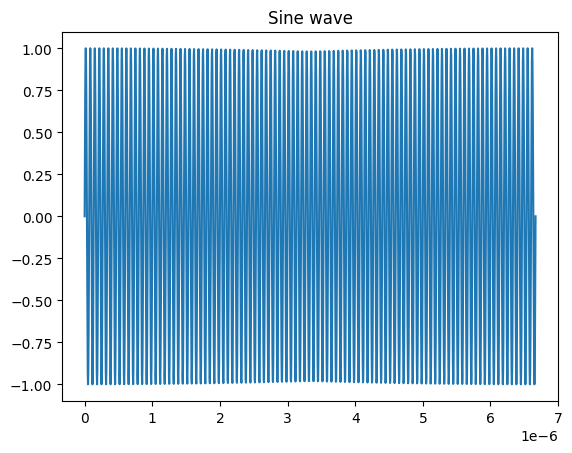

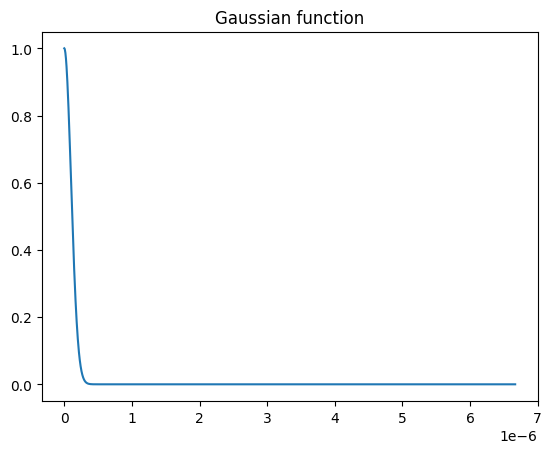

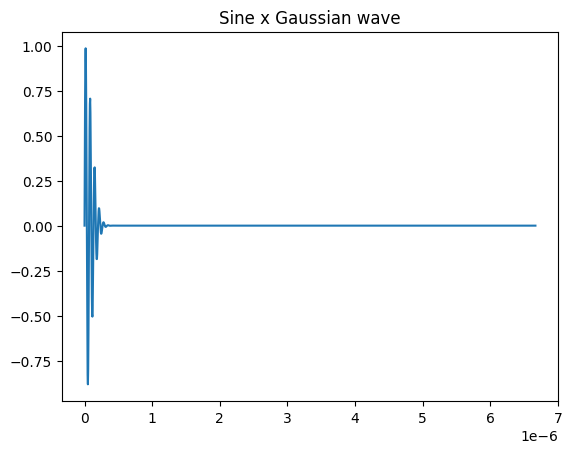

In [128]:
gaussian_std = 0.0000001

def sine_wave(frequency, timestep):
    return np.sin(2*np.pi*frequency*timestep )#+ np.pi/2)

def gaussian_function(timestep, std):
    return np.exp(-timestep**2 / (2 * std**2))

def generate_wave(frequency, timestep, std):
    return sine_wave(frequency, timestep) * gaussian_function(timestep, std)

wave = sine_wave(frequency, time)
plt.plot(time, wave)
plt.title("Sine wave")
plt.show()

wave = gaussian_function(time, gaussian_std)
plt.plot(time, wave)
plt.title("Gaussian function")
plt.show()

wave = generate_wave(frequency, time, gaussian_std)
plt.plot(time, wave)
plt.title("Sine x Gaussian wave")
plt.show()

# DAS (delay and sum)

In [129]:
def delay_function(object_depth, object_position, speed_sound, array_position, pitch):
    return (object_depth / speed_sound) + np.sqrt(object_depth**2 + (array_position * pitch - object_position)**2) / speed_sound

In [130]:
delays = np.zeros(array_length)

for i in range(0, obj_nbr):
    for j in range(0, array_length):
        objects[i].delays[j] = delay_function(object_depth=objects[i].depth, object_position=objects[i].position, speed_sound=c, array_position=j, pitch=pitch)
        delays[j] += objects[i].delays[j]

## Showing delay results

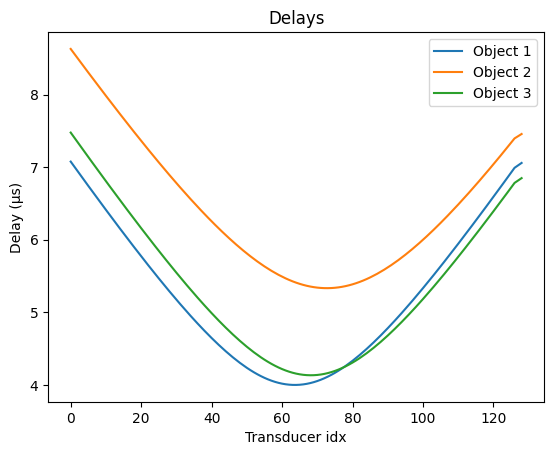

In [131]:
plt.figure()    
for i in range(0, obj_nbr):
    plt.plot(pos, objects[i].delays*1e6, label = f"Object {i+1}")
plt.title("Delays")
plt.xlabel("Transducer idx")
plt.ylabel("Delay (µs)")
plt.legend()
plt.show()

## Showing sum of delays

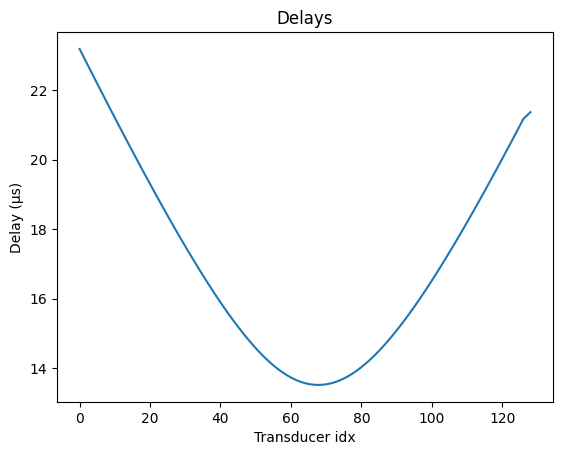

In [132]:
plt.figure()    
plt.plot(pos, delays*1e6)
plt.title("Delays")
plt.xlabel("Transducer idx")
plt.ylabel("Delay (µs)")
plt.show()

## Adding Wave

In [133]:
def generate_apodization(array_length, index, offset=0, mirror=False):
    if index >= 0 and index < array_length / 2:
        if mirror:
            return -1 + offset
        else:
            return 1 + offset
    elif index>=array_length/2 and index < array_length:
        if mirror:
            return 1 + offset
        else:
            return -1 + offset
    else:
        print("Problem with index: ", index)

In [134]:
rf_matrix_zm_summed = np.zeros((samples, array_length))
rf_matrix_dc1_summed = np.zeros((samples, array_length))
rf_matrix_dc2_summed = np.zeros((samples, array_length))

for i in range(0, obj_nbr):
    for j in range(array_length):
        apodization_zm = generate_apodization(array_length, j)
        #for each transducer, generate the wave with the corresponding delay
        objects[i].rf_matrix_zm[:, j] = apodization_zm * generate_wave(frequency, time - objects[i].delays[j], gaussian_std)
        rf_matrix_zm_summed += objects[i].rf_matrix_zm

        apodization_dc1 = generate_apodization(array_length, j, offset=0.5)
        objects[i].rf_matrix_dc1[:, j] = apodization_dc1 * generate_wave(frequency, time - objects[i].delays[j], gaussian_std)
        rf_matrix_dc1_summed += objects[i].rf_matrix_dc1

        apodization_dc2 = generate_apodization(array_length, j, offset=0.5, mirror=True)
        objects[i].rf_matrix_dc2[:, j] = apodization_dc2 * generate_wave(frequency, time - objects[i].delays[j], gaussian_std)
        rf_matrix_dc2_summed += objects[i].rf_matrix_dc2

## Showing wave results

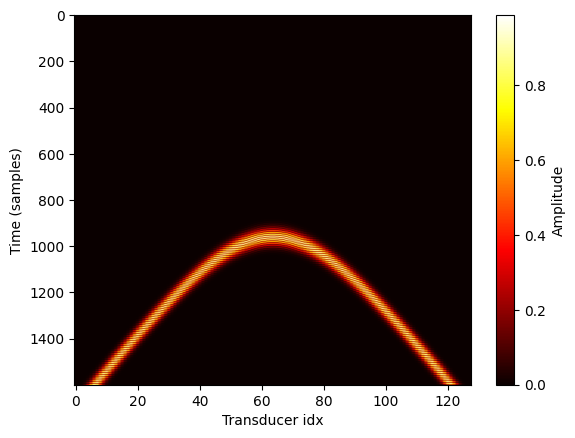

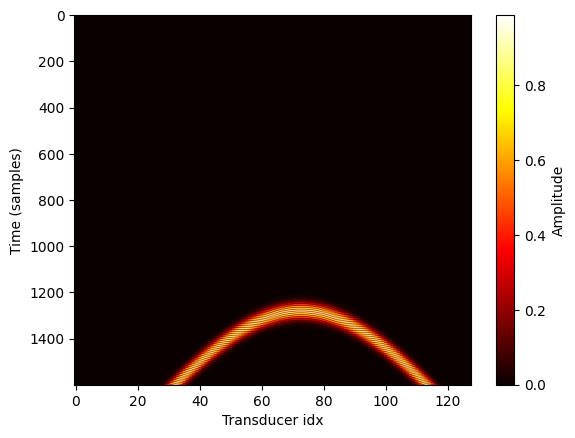

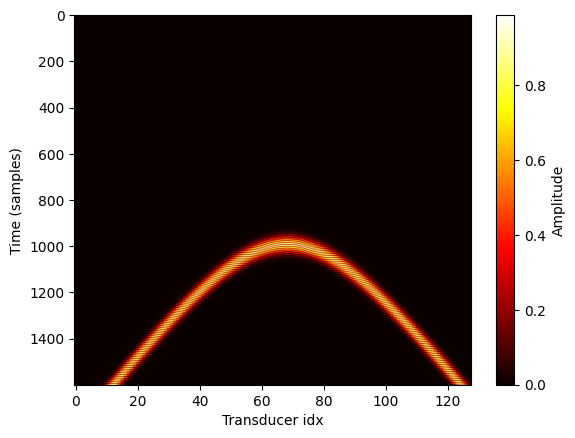

In [135]:
for i in range(0, obj_nbr): #add visu for all offsets
    plt.figure()
    plt.imshow(abs(objects[i].rf_matrix_zm), cmap='hot', aspect='auto')
    plt.xlabel("Transducer idx")
    plt.ylabel("Time (samples)")
    plt.colorbar(label="Amplitude")
    plt.show()

## Showing summed wave results

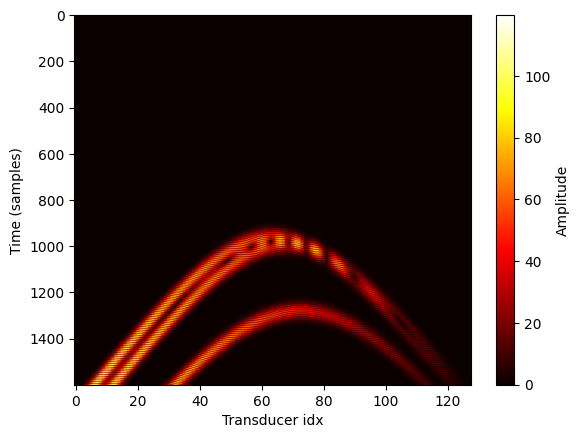

In [136]:
plt.imshow(abs(rf_matrix_zm_summed), cmap='hot', aspect='auto')
plt.xlabel("Transducer idx")
plt.ylabel("Time (samples)")
plt.colorbar(label="Amplitude")
plt.show()

## Applying sum

In [137]:
bf_matrix_zm = np.zeros((samples, array_length))
bf_matrix_dc1 = np.zeros((samples, array_length))
bf_matrix_dc2 = np.zeros((samples, array_length))

total_depth_sample = total_depth / samples  #total depth in m / number of samples = depth per sample

for j in range(0, array_length):
    for k in range(0, samples):

        depth = total_depth_sample*k
        position = pitch*j

        for l in range(0, array_length):

            delay = delay_function(object_depth=depth, object_position=position, speed_sound=c, array_position=l, pitch=pitch)
            delay_idx = int(delay * sampling_rate) #delay in s * sampling rate in 1/s = delay in samples (number of samples to reach delay)

            if delay_idx < samples:
                bf_matrix_zm[k,j] += rf_matrix_zm_summed[delay_idx, l] #we take sample in calculated rf_matrix (faster than recalculating)
                bf_matrix_dc1[k,j] += rf_matrix_dc1_summed[delay_idx, l]
                bf_matrix_dc2[k,j] += rf_matrix_dc2_summed[delay_idx, l]

In [155]:
from scipy.signal import envelope

env_zm = envelope(bf_matrix_zm, residual=None)
env_dc1 = envelope(bf_matrix_dc1, residual=None)
env_dc2 = envelope(bf_matrix_dc2, residual=None)


## NSI

In [156]:
envelope_nsi = (env_dc1 + env_dc2)  / 2 - env_zm

In [157]:
scaled_envelope_nsi = 20 * np.log10(envelope_nsi) - np.max(20 * np.log10(envelope_nsi))

C:\Users\Acer\AppData\Local\Temp\ipykernel_15736\3923238895.py:1: RuntimeWarning: divide by zero encountered in log10
  scaled_envelope_nsi = 20 * np.log10(envelope_nsi) - np.max(20 * np.log10(envelope_nsi))


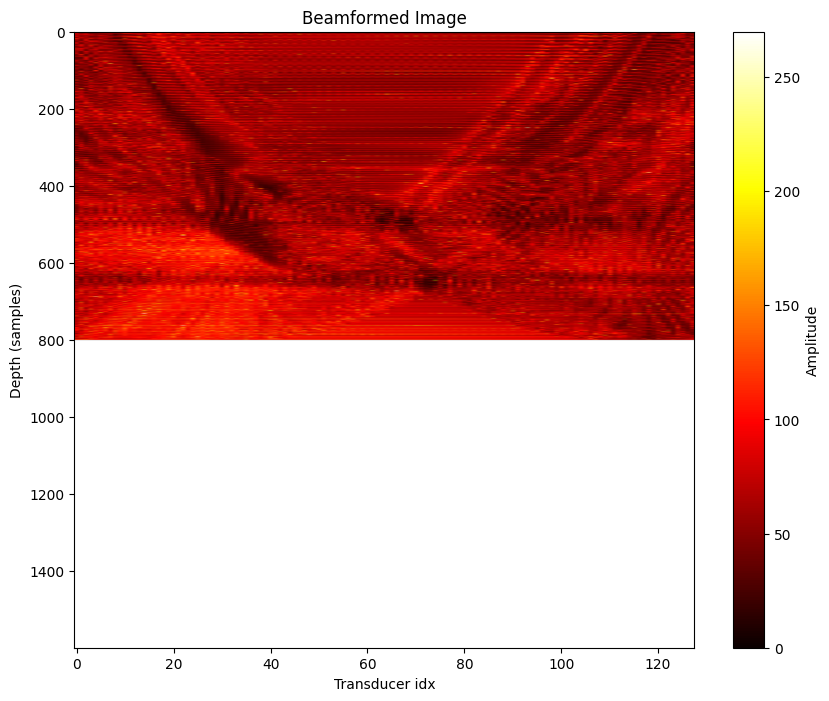

In [160]:
bf_matrix_zm.tofile(f"./data/csv/nsi/bf_matrix_zm.csv", sep=",")
plt.figure(figsize=(10, 8))
plt.imshow(np.abs(scaled_envelope_nsi), cmap='hot', aspect='auto')
plt.title("Beamformed Image")
plt.xlabel("Transducer idx")
plt.ylabel("Depth (samples)")
plt.colorbar(label="Amplitude")
plt.savefig("./data/images/bf_zm_image.png")
plt.show()